# Examples of Unitaries Evolutions

In [22]:
%reload_ext autoreload

import numpy as np 
import matplotlib.pyplot as plt
import math as math 
import cmath as cmath
from scipy import linalg as linalg
from scipy import integrate as integ
from scipy.integrate import solve_ivp



import sys
import os
sys.path.append(os.path.abspath('../src'))

from Objects import Quantum_State, Hamiltonian,Decoherence, Symplectic
from QIT_Functions import Extract_Qubit_Labels_Array


## Time-Dependent Gaussian Open Dynamics: Parametrically Driven QHO

H(t) = diag(1 + Δω sin(2t), 1) — parametric drive at twice the natural frequency (Mathieu equation).
Zero decoherence to verify the unitary limit.

This is a time dependent gaussian Hamiltonian
Initializing a Gaussian State


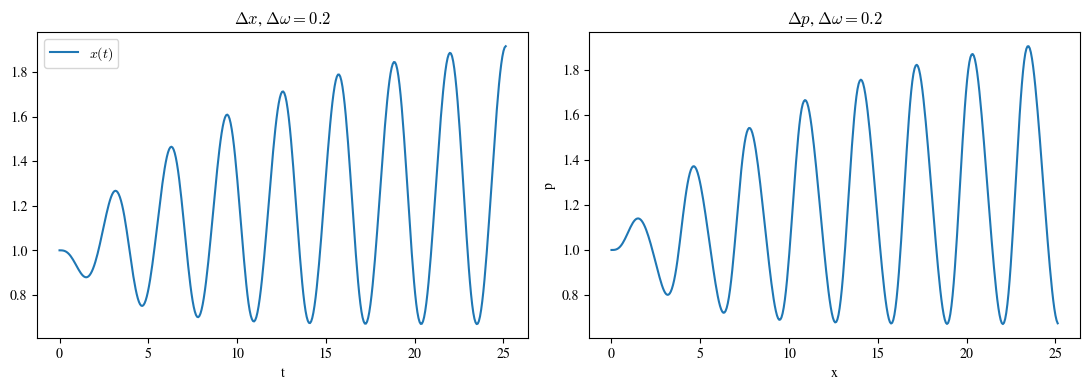

In [23]:
n_modes = 1
Delta_omega = 0.2
gamma_C = 0.2
phi_array = np.array( [0,0.1])
phi= 0

def H_m_driven(t):
    return np.array([[1 + Delta_omega * np.sin(2*t+phi), 0.0],
                     [0.0,                              1.0]])

def r_m_driven(t):
    return np.zeros((2*n_modes, 1))

t_array = np.linspace(0, 8*np.pi, 400)

H_driven = Hamiltonian(0, n_modes)
H_driven.Initialize_Time_Dep_Hamiltonian([H_m_driven], [r_m_driven], [], t_array)

s = 1
dx = 0
r_0     = np.array([[dx], [0.0]])
sigma_0 = np.array([[s,0],[0,1/s]])

gs = Quantum_State(0, n_modes)
gs.Initialize_Gaussian_State(r_0, sigma_0, np.ones((1, 1)))


B_a = gamma_C*np.array([[0.,1.],[0.,0.]])

Dec = Decoherence(0,n_modes,'Ladder', B_a)


gs.Open_Dynamics_Numerical(H_driven, Dec, t_array)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(t_array, np.real(gs.sigma_t[:, 0,0]), label=r'$x(t)$')
axes[0].set_xlabel('t')
axes[0].legend()
axes[0].set_title(fr'$\Delta x$, $\Delta\omega={Delta_omega}$')

axes[1].plot(t_array, np.real(gs.sigma_t[:, 1,1]), label=r'$p(t)$')
axes[1].set_xlabel('x')
axes[1].set_ylabel('p')
axes[1].set_title(fr'$\Delta p$, $\Delta\omega={Delta_omega}$')

plt.tight_layout()
plt.show()

/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/lorenzobraccini/GitHub/GCS/src/Wigner_Functions.py:121: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Gausss[m,n] += (2**n_modes)/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] -r_first)@sigma_inv@(r_tilde_array[m,n] - r_first))[0,0]


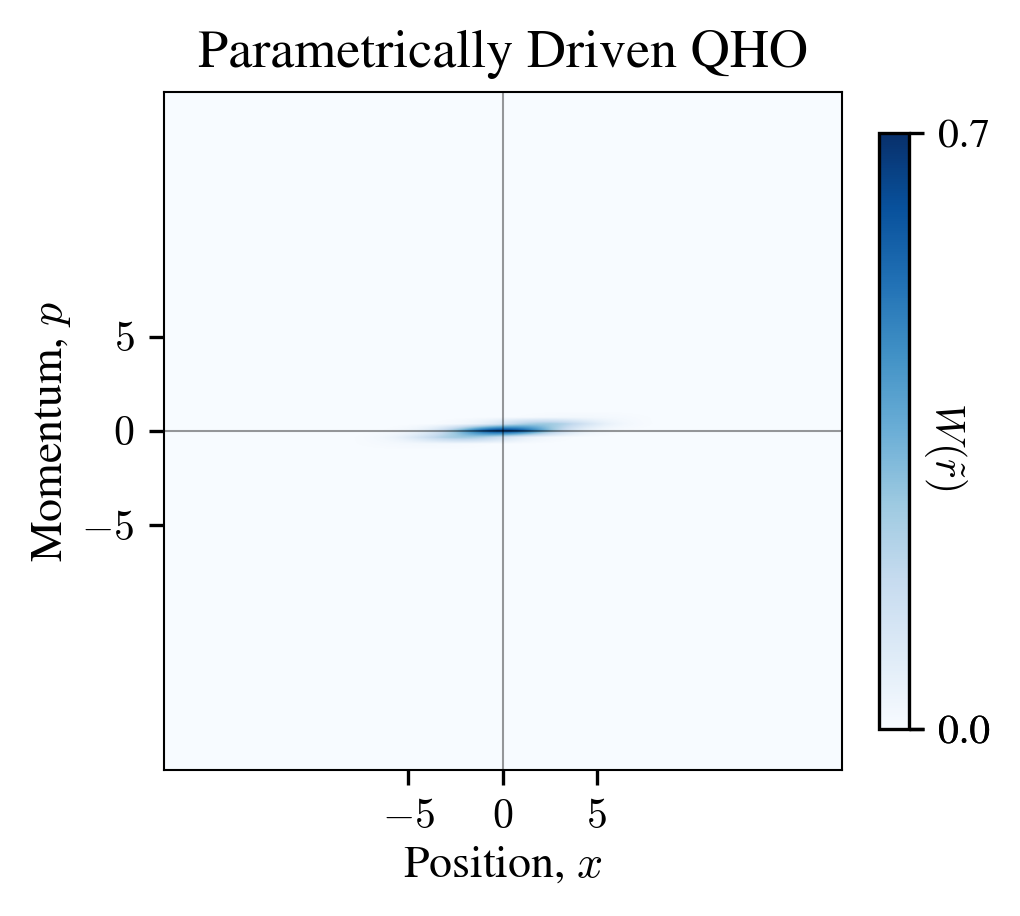

In [21]:
steps = 101
mode_number = 0
time_index = 40
bar_limits = [0,0.5]
sigma_para = 1.3
array_tick = np.linspace(-5,5,3)
n_frames = len(gs.t_array)

gs.Animate_Gaussian(steps, mode_number, sigma_para, array_tick, n_frames, "Parametrically Driven QHO" , 'driven_harmonic.gif')

## Centered Pancake (Off-diagonal Covariance) in 3-D Phase Space

For an off-diagonal GCS element the covariance matrix is

$$
\sigma^{\text{off}} =
\begin{pmatrix}
  e^{i\psi}|\zeta| & 0 \\\\
  0 & e^{-i\psi}/|\zeta|
\end{pmatrix}
$$

with

$$
\zeta^2 = \frac{\cos^2\theta_\Delta + s^2\sin^2\theta_\Delta}
               {\sin^2\theta_\Delta + s^2\cos^2\theta_\Delta}
$$

In the 3-D phase-space $(\mathrm{Re}[x],\,\mathrm{Re}[p],\,\mathrm{Im}[x])$
this is a **flat 2-D ellipse** (pancake) with centre at the origin ($r=0$)
and semi-axes $\sqrt{|\zeta|}$ and $1/\sqrt{|\zeta|}$, lying in the plane
spanned by

$$
\mathbf{u} = (\cos\psi,\,0,\,\sin\psi), \qquad
\mathbf{v} = (0,\,1,\,0)
$$

so the unit normal is $\hat{n} = (-\sin\psi,\,0,\,\cos\psi)$.
At $\psi=0$ the pancake lies flat in the $xy$-plane; increasing $\psi$ tilts it
toward the $\mathrm{Im}[x]$ axis.

In [ ]:
import matplotlib.lines as mlines
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from Plots_Functions import (_make_scene_3d, _finalise_3d, _draw_vector_3d)


def zeta_from_params(theta_Delta, s):
    """
    |ζ| from branching angle θ_Δ and squeezing ratio s.
    ζ² = (cos²θ_Δ + s² sin²θ_Δ) / (sin²θ_Δ + s² cos²θ_Δ)
    """
    c2, s2 = np.cos(theta_Delta)**2, np.sin(theta_Delta)**2
    return np.sqrt((c2 + s**2 * s2) / (s2 + s**2 * c2))


def sigma_off_matrix(zeta_abs, psi):
    """σ^off = diag(e^{iψ}|ζ|, e^{-iψ}/|ζ|) as a 2×2 complex ndarray."""
    return np.diag([np.exp(1j * psi) * zeta_abs,
                    np.exp(-1j * psi) / zeta_abs])


def Plot_Pancake_3D(zeta_abs, psi,
                    sym_lim=2.0, figsize=(8, 8), elev=22, azim=-55,
                    color='tomato', alpha_fill=0.22, n_pts=300,
                    title=''):
    """
    Draw a centered 'pancake' (flat 2-D ellipse) in the GCS 3-D phase space
    (Re[x], Re[p], Im[x]).

    Off-diagonal covariance: σ^off = diag(e^{iψ}|ζ|, e^{-iψ}/|ζ|)

    Pancake plane spanned by:
        u = (cos ψ, 0, sin ψ)   semi-axis √|ζ|
        v = (0,     1,    0 )   semi-axis 1/√|ζ|
    Normal: n = u × v = (−sin ψ, 0, cos ψ)

    Overlays
    --------
    · filled face + solid edge  — the pancake
    · dotted ellipse            — projection onto Im[x] = 0
    · arrow                     — unit normal n̂

    Parameters
    ----------
    zeta_abs  : float > 0   |ζ|
    psi       : float (rad) tilt angle; ψ=0 → pancake lies flat in xy-plane
    sym_lim   : float       symmetric half-range for all three axes
    figsize   : (w, h)
    elev,azim : 3-D view angles (degrees)
    color     : face/edge colour of the pancake
    alpha_fill: face transparency (0–1)
    n_pts     : number of perimeter sample points
    title     : optional title string

    Returns
    -------
    fig, ax : Figure and Axes3D
    """
    theta = np.linspace(0, 2 * np.pi, n_pts)
    a = np.sqrt(zeta_abs)         # semi-axis along u
    b = 1.0 / np.sqrt(zeta_abs)  # semi-axis along v

    # Orthonormal basis of the pancake plane in (Re[x], Re[p], Im[x])
    u = np.array([ np.cos(psi), 0.0, np.sin(psi)])
    v = np.array([0.0,          1.0, 0.0        ])
    n = np.array([-np.sin(psi), 0.0, np.cos(psi)])  # u × v

    # Parametric 3-D ellipse, shape (n_pts, 3)
    P = np.outer(a * np.cos(theta), u) + np.outer(b * np.sin(theta), v)

    # Projection onto Im[x] = 0 plane
    P_proj      = P.copy()
    P_proj[:, 2] = 0.0

    # ── scene ──────────────────────────────────────────────────────────────
    fig, ax = _make_scene_3d((-sym_lim, sym_lim), z_comp=0,
                             figsize=figsize, elev=elev, azim=azim)

    # ── filled pancake face ────────────────────────────────────────────────
    verts = [list(zip(P[:, 0], P[:, 1], P[:, 2]))]
    ax.add_collection3d(
        Poly3DCollection(verts, facecolor=color, edgecolor='none',
                         alpha=alpha_fill, zorder=4))

    # Solid perimeter edge
    ax.plot(P[:, 0], P[:, 1], P[:, 2],
            color=color, linewidth=1.8, alpha=0.9, zorder=5)

    # ── xy-plane projection (dotted loop) ──────────────────────────────────
    ax.plot(P_proj[:, 0], P_proj[:, 1], P_proj[:, 2],
            linestyle=':', color='dimgray', linewidth=1.4, alpha=0.85, zorder=3)

    # Thin vertical drop-lines from pancake edge down to its xy projection
    step = max(1, n_pts // 32)
    for i in range(0, n_pts, step):
        ax.plot([P[i, 0], P_proj[i, 0]],
                [P[i, 1], P_proj[i, 1]],
                [P[i, 2], 0.0],
                color='gray', linewidth=0.4, alpha=0.35, linestyle='--')

    # ── unit normal arrow ──────────────────────────────────────────────────
    _draw_vector_3d(ax, n * 0.75 * sym_lim, color='black', lw=1.8)

    # ── legend + axis labels ───────────────────────────────────────────────
    handles = [
        Patch(facecolor=color, alpha=0.6,
              label=r'$\sigma^{\mathrm{off}}$ pancake'),
        mlines.Line2D([], [], color='dimgray', linestyle=':', linewidth=1.4,
                      label=r'$xy$-plane projection'),
        mlines.Line2D([], [], color='black', linewidth=1.8,
                      label=r'normal $\hat{n}$'),
    ]
    _finalise_3d(ax, fig, (-sym_lim, sym_lim), z_comp=0,
                 title=title, legend_handles=handles)

    return fig, ax


In [ ]:
# Physical parameters
theta_Delta = np.pi / 6   # branching angle θ_Δ
s_param     = 3.0          # squeezing ratio s

zeta_val = zeta_from_params(theta_Delta, s_param)
psi_val  = np.pi / 4       # tilt angle ψ = 45°

print(f"|ζ|  = {zeta_val:.4f}   (ζ² = {zeta_val**2:.4f})")
print(f"Semi-axes: √|ζ| = {np.sqrt(zeta_val):.4f},  1/√|ζ| = {1/np.sqrt(zeta_val):.4f}")
print(f"σ_off =\n{sigma_off_matrix(zeta_val, psi_val)}")

# azim=160, elev=35: nearly face-on view so the pancake is clearly visible
fig, ax = Plot_Pancake_3D(
    zeta_val, psi_val,
    sym_lim=2.0, elev=35, azim=160, color='tomato',
    title=rf'Pancake: $|\zeta|={zeta_val:.2f}$, $\psi = \pi/4$')
plt.show()
